In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 1. Important Patterns

Important patterns are repeated behaviors or noticeable differences in the data that may help explain business performance.

In this restaurant dataset, we will examine bill amounts, tips, customer visit days, party sizes, and dining periods to identify useful patterns.

In [2]:
print("Average total bill:", round(df["total_bill"].mean(), 2))
print("Average tip:", round(df["tip"].mean(), 2))
print("Average party size:", round(df["size"].mean(), 2))

print("\nAverage tip by day:")
display(
    df.groupby("day", observed=False)["tip"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
    .to_frame("Average Tip")
)

print("\nNumber of records by day:")
display(df["day"].value_counts().to_frame("Transactions"))

Average total bill: 19.79
Average tip: 3.0
Average party size: 2.57

Average tip by day:


,Average Tip
day,
Sun,3.26
Sat,2.99
Thur,2.77
Fri,2.73



Number of records by day:


,Transactions
day,
Sat,87
Sun,76
Thur,62
Fri,19


## 2. Relationships Between Variables

Relationships help us understand how one variable changes alongside another. Examining the relationship between total bill and tip can help describe customer tipping behavior.

A relationship does not necessarily mean one variable causes the other.

Correlation between total bill and tip: 0.676


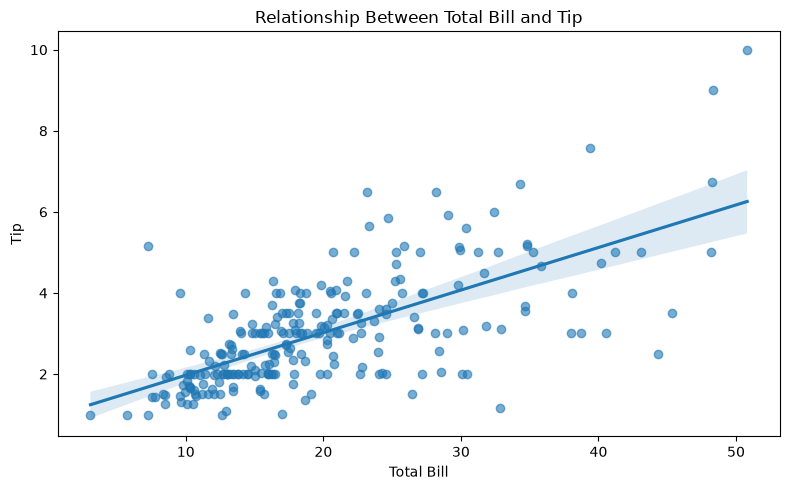

In [3]:
correlation = df["total_bill"].corr(df["tip"])

print("Correlation between total bill and tip:", round(correlation, 3))

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="total_bill", y="tip", scatter_kws={"alpha": 0.6})

plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.tight_layout()
plt.show()

## 3. Interesting Segments

Customer segmentation groups observations with shared characteristics. In this analysis, we compare average tips across dining periods, days, and party sizes to identify segments with different observed tipping behavior.

In [4]:
print("Average tip by dining period:")
display(
    df.groupby("time", observed=False)
    .agg(
        Average_Tip=("tip", "mean"),
        Average_Bill=("total_bill", "mean"),
        Transactions=("tip", "size")
    )
    .round(2)
)

print("\nAverage tip by party size:")
display(
    df.groupby("size")
    .agg(
        Average_Tip=("tip", "mean"),
        Average_Bill=("total_bill", "mean"),
        Transactions=("tip", "size")
    )
    .round(2)
)

Average tip by dining period:


,Average_Tip,Average_Bill,Transactions
time,,,
Lunch,2.73,17.17,68
Dinner,3.10,20.80,176



Average tip by party size:


,Average_Tip,Average_Bill,Transactions
size,,,
1,1.44,7.24,4
2,2.58,16.45,156
3,3.39,23.28,38
4,4.14,28.61,37
5,4.03,30.07,5
6,5.22,34.83,4


## 4. Business Activity Across Days

**Observation:** Comparing transaction counts and average bills across days helps identify differences in restaurant activity.

**Insight:** The day with the most recorded transactions may not have the highest average bill.

**Business implication:** Restaurant managers could use these differences as a starting point for investigating staffing, promotions, and inventory requirements. The dataset alone cannot establish the causes of these patterns.

,Transactions,Average_Bill,Total_Bill,Average_Tip
day,,,,
Thur,62,17.68,1096.33,2.77
Fri,19,17.15,325.88,2.73
Sat,87,20.44,1778.40,2.99
Sun,76,21.41,1627.16,3.26


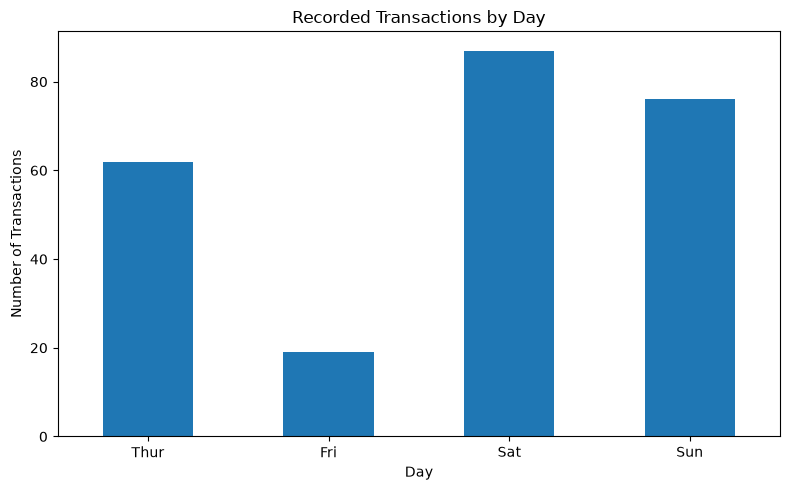

In [5]:
daily_summary = (
    df.groupby("day", observed=False)
    .agg(
        Transactions=("total_bill", "count"),
        Average_Bill=("total_bill", "mean"),
        Total_Bill=("total_bill", "sum"),
        Average_Tip=("tip", "mean")
    )
    .round(2)
)

display(daily_summary)

daily_summary["Transactions"].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Recorded Transactions by Day")
plt.xlabel("Day")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Anomaly Detection

**Observation:** Some restaurant bills may be unusually high compared with the rest of the dataset.

**Insight:** These observations could represent large parties, expensive orders, or data-entry errors.

**Business implication:** Investigate unusual transactions before making operational decisions. A high bill is not automatically an error and should not be removed without justification.

In [6]:
Q1 = df["total_bill"].quantile(0.25)
Q3 = df["total_bill"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

unusual_bills = df[df["total_bill"] > upper_bound]

print("Upper IQR threshold:", round(upper_bound, 2))
print("Number of unusually high bills:", len(unusual_bills))

display(
    unusual_bills[
        ["total_bill", "tip", "size", "day", "time"]
    ].sort_values("total_bill", ascending=False)
)

Upper IQR threshold: 40.3
Number of unusually high bills: 9


,total_bill,tip,size,day,time
170,50.81,10.00,3,Sat,Dinner
212,48.33,9.00,4,Sat,Dinner
59,48.27,6.73,4,Sat,Dinner
156,48.17,5.00,6,Sun,Dinner
182,45.35,3.50,3,Sun,Dinner
102,44.30,2.50,3,Sat,Dinner
197,43.11,5.00,4,Thur,Lunch
142,41.19,5.00,5,Thur,Lunch
184,40.55,3.00,2,Sun,Dinner


## 6. Potential Business Problems

Exploratory analysis can highlight questions that a business may need to investigate.

- **Variation in bills:** Different spending levels may require different service approaches.
- **Differences between days:** Uneven transaction counts may affect staffing and inventory planning.
- **Variation in tips:** Tip amounts may differ across bill sizes, party sizes, or dining periods.
- **Unusual transactions:** High bills should be checked for accuracy and understood in context.

These are potential investigation areas, not confirmed business problems. Additional operational and cost data would be needed to establish actual causes.

In [7]:
segment_summary = (
    df.groupby(["time", "size"], observed=False)
    .agg(
        Transactions=("total_bill", "count"),
        Average_Bill=("total_bill", "mean"),
        Average_Tip=("tip", "mean")
    )
    .round(2)
    .sort_values("Transactions", ascending=False)
)

display(segment_summary.head(10))

Transactions  Average_Bill  Average_Tip
time   size                                         
Dinner 2              104         17.23         2.66
Lunch  2               52         14.89         2.42
Dinner 3               33         24.00         3.49
       4               32         28.40         4.12
Lunch  3                5         18.52         2.75
       4                5         29.95         4.22
Dinner 5                4         27.29         3.78
Lunch  6                3         30.38         5.30
       1                2          9.32         1.88
Dinner 1                2          5.16         1.00

## 7. Potential Business Opportunities

The analysis can help generate hypotheses for future business improvements:

1. **Staffing optimization:** Compare transaction volumes across days and dining periods.
2. **Customer experience:** Investigate factors associated with higher or lower tips.
3. **Group dining:** Study spending patterns for different party sizes.
4. **Service improvement:** Investigate unusual transactions and differences between customer segments.

These opportunities should be validated with more data before implementing changes.

## Conclusion

In this notebook, I converted exploratory data analysis results into business observations and potential recommendations. I examined transaction patterns across days, relationships between bills and tips, differences between customer segments, and unusually high bills.

The findings can help generate hypotheses about staffing, customer experience, group dining, and transaction monitoring. However, the `tips` dataset is a small practice dataset and does not contain information about costs, profit, staffing, or customer history. Therefore, the recommendations require further validation before being used for real business decisions.

The objective is to move from visualization to observation, from observation to insight, and from insight to a practical recommendation supported by evidence.